In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from STS_amplifier.surrogate.generate_sts_1d import generate_sts_1d_dataset
from STS_amplifier.surrogate.train import train_surrogate
from STS_amplifier.surrogate.predict import predict

In [23]:
DATA_DIR = "../data"
ART_DIR  = "../surrogate_artifacts"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(ART_DIR, exist_ok=True)

STS_EC = 48e5 * 2*np.pi
STS_EL = 1650e9 * 2*np.pi

n_lo = 20
n_hi = 120

N_full = 60
N_hi = 20

lam_min = -1.90
lam_max = 0.0
lam_hi_max = -1.75

In [24]:
lo_path = f"{DATA_DIR}/sts_lo_full.npz"
hi_path = f"{DATA_DIR}/sts_hi_region.npz"

generate_sts_1d_dataset(
    out_npz=lo_path,
    nsamples=N_full,
    n_levels=n_lo,
    STS_EC=STS_EC,
    STS_EL=STS_EL,
    lam_norm_min=lam_min,
    lam_norm_max=lam_max,
    sample_mode="grid",
)

generate_sts_1d_dataset(
    out_npz=hi_path,
    nsamples=N_hi,
    n_levels=n_hi,
    STS_EC=STS_EC,
    STS_EL=STS_EL,
    lam_norm_min=lam_min,
    lam_norm_max=lam_hi_max,
    sample_mode="grid",
)

generated 6/60
generated 12/60
generated 18/60
generated 24/60
generated 30/60
generated 36/60
generated 42/60
generated 48/60
generated 54/60
generated 60/60
saved dataset: ../data/sts_lo_full.npz
generated 2/20
generated 4/20
generated 6/20
generated 8/20
generated 10/20
generated 12/20
generated 14/20
generated 16/20
generated 18/20
generated 20/20
saved dataset: ../data/sts_hi_region.npz


In [25]:
lo_model_dir = f"{ART_DIR}/sts_lo"

train_surrogate(
    data_npz=lo_path,
    out_dir=lo_model_dir,
    epochs=600,
    batch_size=16,
    lr=1e-3,
    hidden=32,
    seed=0,
)

epoch 001 | val_mse=2.2413e+01
epoch 002 | val_mse=2.2101e+01
epoch 003 | val_mse=2.1785e+01
epoch 004 | val_mse=2.1470e+01
epoch 005 | val_mse=2.1143e+01
epoch 006 | val_mse=2.0793e+01
epoch 007 | val_mse=2.0421e+01
epoch 008 | val_mse=2.0019e+01
epoch 009 | val_mse=1.9595e+01
epoch 010 | val_mse=1.9155e+01
epoch 011 | val_mse=1.8710e+01
epoch 012 | val_mse=1.8258e+01
epoch 013 | val_mse=1.7792e+01
epoch 014 | val_mse=1.7325e+01
epoch 015 | val_mse=1.6826e+01
epoch 016 | val_mse=1.6305e+01
epoch 017 | val_mse=1.5754e+01
epoch 018 | val_mse=1.5191e+01
epoch 019 | val_mse=1.4593e+01
epoch 020 | val_mse=1.3987e+01
epoch 021 | val_mse=1.3380e+01
epoch 022 | val_mse=1.2733e+01
epoch 023 | val_mse=1.2063e+01
epoch 024 | val_mse=1.1371e+01
epoch 025 | val_mse=1.0685e+01
epoch 026 | val_mse=9.9700e+00
epoch 027 | val_mse=9.2522e+00
epoch 028 | val_mse=8.5372e+00
epoch 029 | val_mse=7.8317e+00
epoch 030 | val_mse=7.1104e+00
epoch 031 | val_mse=6.3808e+00
epoch 032 | val_mse=5.6817e+00
epoch 03

In [26]:
delta_path = f"{DATA_DIR}/sts_delta_region.npz"

hi = np.load(hi_path)
X_hi = hi["X"]
y_hi = hi["y"]
lam_norm_hi = hi["lam_norm"]

y_lo_at_hi = predict(lo_model_dir, X_hi)
y_delta = y_hi - y_lo_at_hi

np.savez_compressed(delta_path, X=X_hi, y=y_delta, lam_norm=lam_norm_hi)
print("saved:", delta_path)

saved: ../data/sts_delta_region.npz


In [27]:
delta_model_dir = f"{ART_DIR}/sts_delta"

train_surrogate(
    data_npz=delta_path,
    out_dir=delta_model_dir,
    epochs=600,
    batch_size=16,
    lr=1e-3,
    hidden=16,
    seed=0,
)

epoch 001 | val_mse=3.8489e+01
epoch 002 | val_mse=3.8369e+01
epoch 003 | val_mse=3.8252e+01
epoch 004 | val_mse=3.8136e+01
epoch 005 | val_mse=3.8020e+01
epoch 006 | val_mse=3.7911e+01
epoch 007 | val_mse=3.7804e+01
epoch 008 | val_mse=3.7694e+01
epoch 009 | val_mse=3.7582e+01
epoch 010 | val_mse=3.7476e+01
epoch 011 | val_mse=3.7373e+01
epoch 012 | val_mse=3.7268e+01
epoch 013 | val_mse=3.7165e+01
epoch 014 | val_mse=3.7063e+01
epoch 015 | val_mse=3.6961e+01
epoch 016 | val_mse=3.6854e+01
epoch 017 | val_mse=3.6743e+01
epoch 018 | val_mse=3.6632e+01
epoch 019 | val_mse=3.6521e+01
epoch 020 | val_mse=3.6400e+01
epoch 021 | val_mse=3.6237e+01
epoch 022 | val_mse=3.6049e+01
epoch 023 | val_mse=3.5854e+01
epoch 024 | val_mse=3.5660e+01
epoch 025 | val_mse=3.5461e+01
epoch 026 | val_mse=3.5249e+01
epoch 027 | val_mse=3.5022e+01
epoch 028 | val_mse=3.4785e+01
epoch 029 | val_mse=3.4541e+01
epoch 030 | val_mse=3.4293e+01
epoch 031 | val_mse=3.4028e+01
epoch 032 | val_mse=3.3744e+01
epoch 03

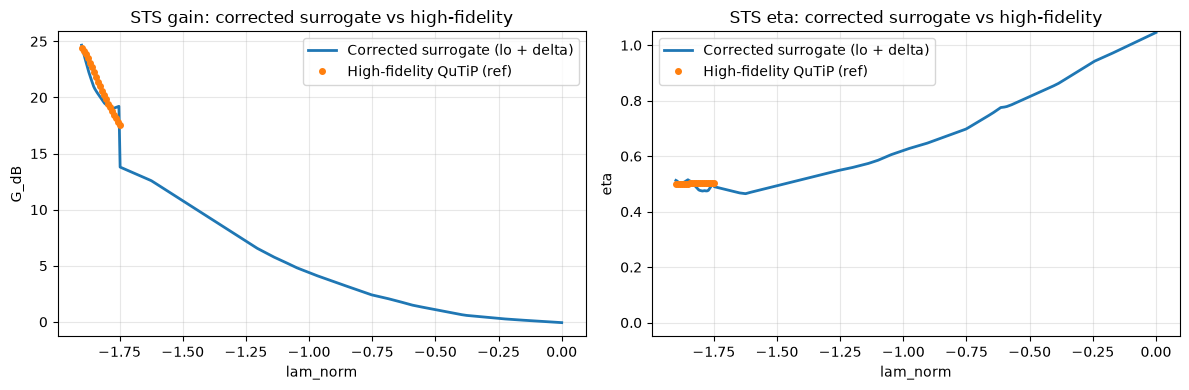

In [28]:
lam_plot = np.linspace(lam_min, lam_max, 400)
X_plot = lam_plot.reshape(-1, 1)

y_lo = predict(lo_model_dir, X_plot)

mask = lam_plot <= lam_hi_max
y_delta_plot = np.zeros_like(y_lo)
y_delta_plot[mask] = predict(delta_model_dir, X_plot[mask])

y_corr = y_lo + y_delta_plot

G_corr = y_corr[:, 0]
eta_corr = y_corr[:, 1]

hi = np.load(hi_path)
lam_hi = hi["lam_norm"]
G_hi = hi["y"][:, 0]
eta_hi = hi["y"][:, 1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(lam_plot, G_corr, lw=2, label="Corrected surrogate (lo + delta)")
ax1.plot(lam_hi, G_hi, "o", ms=4, label="High-fidelity QuTiP (ref)")
ax1.set_xlabel("lam_norm")
ax1.set_ylabel("G_dB")
ax1.set_title("STS gain: corrected surrogate vs high-fidelity")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(lam_plot, eta_corr, lw=2, label="Corrected surrogate (lo + delta)")
ax2.plot(lam_hi, eta_hi, "o", ms=4, label="High-fidelity QuTiP (ref)")
ax2.set_xlabel("lam_norm")
ax2.set_ylabel("eta")
ax2.set_ylim(-0.05, 1.05)
ax2.set_title("STS eta: corrected surrogate vs high-fidelity")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

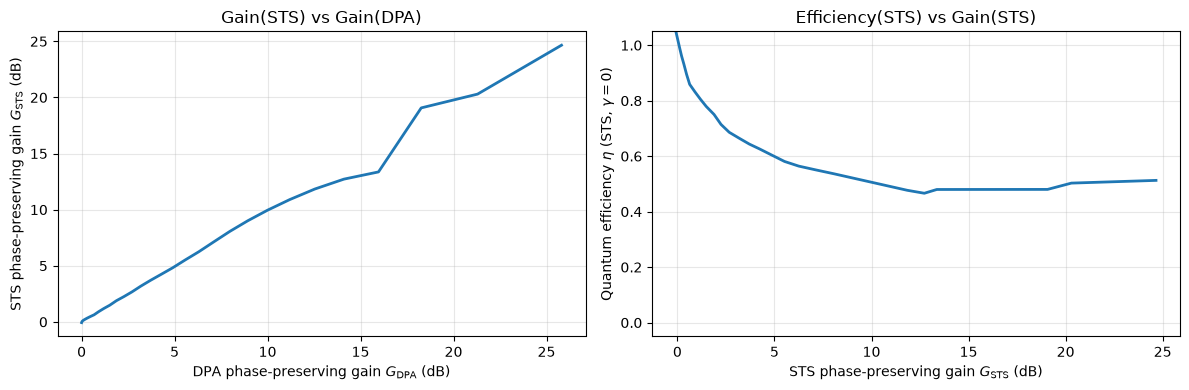

In [29]:
import numpy as np
import matplotlib.pyplot as plt

from STS_amplifier.surrogate.predict import predict
from STS_amplifier.core import parametric_metrics

# ----- paths (adjust if needed) -----
lo_model_dir = "../surrogate_artifacts/sts_lo"
delta_model_dir = "../surrogate_artifacts/sts_delta"

# ----- sweep grid in lam_norm -----
lam_min = -1.9
lam_max = 0.0
lam_hi_max = -1.75   # where your delta model is valid
lam_norm = np.linspace(lam_min, lam_max, 30)
X = lam_norm.reshape(-1, 1)

# ----- STS surrogate prediction: low + delta (with gating) -----
y_lo = predict(lo_model_dir, X)

mask = lam_norm <= lam_hi_max
y_delta = np.zeros_like(y_lo)
y_delta[mask] = predict(delta_model_dir, X[mask])

y_sts = y_lo + y_delta
G_STS_dB = y_sts[:, 0]
eta_STS  = y_sts[:, 1]

# ----- DPA gain computed from QuTiP at same lam values -----
# Constants (must match your conventions)
kappa = 300e6 * 2*np.pi
drive = 0.2
theta = -np.pi/2
phi = 0.0
Delta = 0.0
gamma = 0.0
n_levels_dpa = 40  # keep small for speed; DPA is just a reference axis

def G_DPA_dB_equation_from_lam(lam: np.ndarray, kappa: float, gamma: float = 0.0, Delta: float = 0.0, w: float = 0.0) -> np.ndarray:
    ktot = kappa + gamma
    num = kappa * ktot/2 - 1j * (Delta + w)
    denom = Delta**2 + (ktot/2 - 1j*w)**2 - np.abs(lam)**2
    g_sw = (num / denom) - 1
    G_lin = np.abs(g_sw)**2
    return 10.0 * np.log10(G_lin)

lam = lam_norm * (kappa/4.0)
G_DPA_dB = G_DPA_dB_equation_from_lam(lam, kappa=kappa, gamma=0.0, Delta=0.0, w=0.0)


# ----- filter out any NaNs before plotting -----
good = np.isfinite(G_DPA_dB) & np.isfinite(G_STS_dB) & np.isfinite(eta_STS)
G_DPA_dB = G_DPA_dB[good]
G_STS_dB = G_STS_dB[good]
eta_STS  = eta_STS[good]

# ----- Plot 1: Gain(STS) vs Gain(DPA) -----
# sort by x for clean curve
idx = np.argsort(G_DPA_dB)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(G_DPA_dB[idx], G_STS_dB[idx], lw=2)
ax1.set_xlabel(r"DPA phase-preserving gain $G_{\mathrm{DPA}}$ (dB)")
ax1.set_ylabel(r"STS phase-preserving gain $G_{\mathrm{STS}}$ (dB)")
ax1.set_title("Gain(STS) vs Gain(DPA)")
ax1.grid(True, alpha=0.3)

# ----- Plot 2: eta(STS) vs Gain(STS) -----
idx2 = np.argsort(G_STS_dB)
ax2.plot(G_STS_dB[idx2], eta_STS[idx2], lw=2)
ax2.set_xlabel(r"STS phase-preserving gain $G_{\mathrm{STS}}$ (dB)")
ax2.set_ylabel(r"Quantum efficiency $\eta$ (STS, $\gamma=0$)")
ax2.set_title("Efficiency(STS) vs Gain(STS)")
ax2.set_ylim(-0.05, 1.05)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
from STS_amplifier.params import STS_params
from STS_amplifier.core import _sweep_G_eta
ratio_STS, phi_STS = STS_params(48e5*2*np.pi, 1650e9*2*np.pi)
G_STS_sim, G_STS_eta_sim, eta_STS_sim = _sweep_G_eta("STS", (48e5*2*np.pi, 1650e9*2*np.pi), 30, Delta, kappa, gamma, drive, 150, theta, phi)

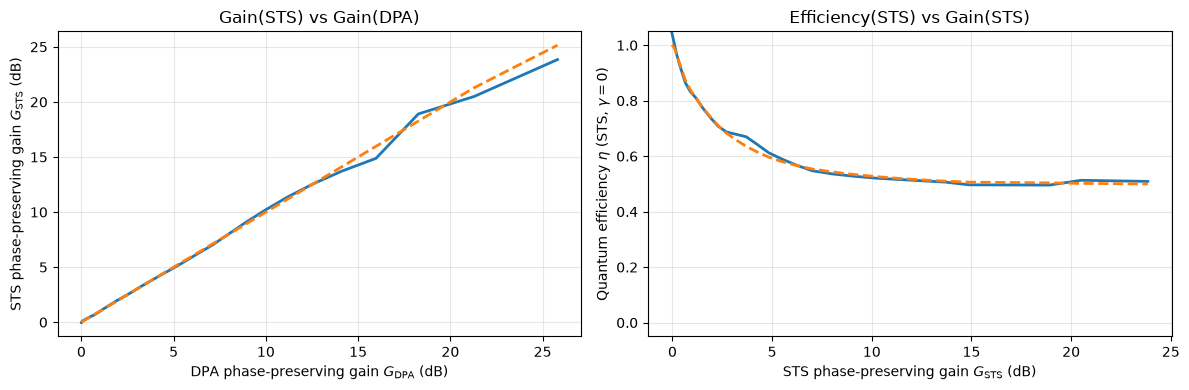

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(G_DPA_dB[idx], G_STS_dB[idx], lw=2)
ax1.plot(G_DPA_dB[idx], G_STS_sim, lw=2, ls="--", label="STS (QuTiP)")
ax1.set_xlabel(r"DPA phase-preserving gain $G_{\mathrm{DPA}}$ (dB)")
ax1.set_ylabel(r"STS phase-preserving gain $G_{\mathrm{STS}}$ (dB)")
ax1.set_title("Gain(STS) vs Gain(DPA)")
ax1.grid(True, alpha=0.3)

idx2 = np.argsort(G_STS_dB)
ax2.plot(G_STS_dB[idx2], eta_STS[idx2], lw=2)
ax2.plot(G_STS_dB[idx2], eta_STS_sim, lw=2, ls="--", label="STS (QuTiP)")
ax2.set_xlabel(r"STS phase-preserving gain $G_{\mathrm{STS}}$ (dB)")
ax2.set_ylabel(r"Quantum efficiency $\eta$ (STS, $\gamma=0$)")
ax2.set_title("Efficiency(STS) vs Gain(STS)")
ax2.set_ylim(-0.05, 1.05)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()